**Question 1:**  
Identify and explain another real-world application of your own where the Law of Large Numbers (LLN) and/or the Central Limit Theorem (CLT) plays a critical role.

**Answer:**  
A practical application of the Law of Large Numbers (LLN) and the Central Limit Theorem (CLT) is A/B testing. In an A/B test, two versions of a product are shown to different groups of consumers to determine whether a redesign or new product is an improvement. One group sees the old version, and the other sees the new one. By gathering data from many users, a company can measure how the overall population responds rather than relying on individual opinions. The LLN ensures that as more users are included, the observed preference rate for each version gets closer to the true rate for the entire customer base. The CLT then allows the company to calculate how confident it can be that the difference between the two versions is real and not just due to chance.

A real-world example can be seen in Microsoft Outlook. Microsoft now lets users choose between the old and new versions of Outlook because many longtime users had grown so used to the older version that they struggled to adapt to the new one. By observing how millions of users respond, Microsoft can rely on the overall pattern of preferences rather than on a few individual complaints or compliments when deciding how to move forward with its design.

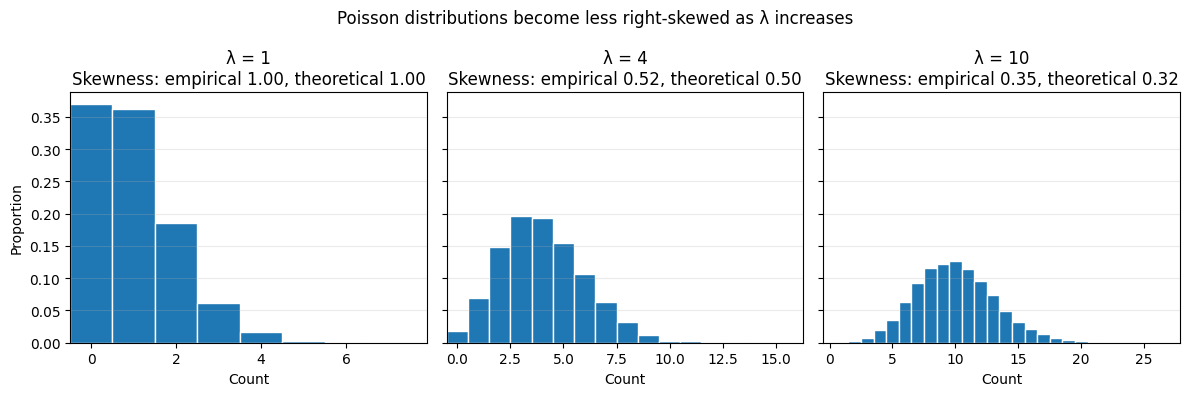

In [9]:
# Question 2A

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(123456)
lambdas = [1, 4, 10]
sims = 10000
samples = {lam: rng.poisson(lam=lam, size=sims) for lam in lambdas}

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, lam in zip(axes, lambdas):
    sample = samples[lam]
    bins = np.arange(-0.5, sample.max() + 1.5, 1)
    empirical_skewness = np.mean((sample - sample.mean()) ** 3) / np.std(sample) ** 3
    theoretical_skewness = 1 / np.sqrt(lam)

    ax.hist(sample, bins=bins, density=True, edgecolor="white")
    ax.set_title(
        f"λ = {lam}\n"
        f"Skewness: empirical {empirical_skewness:.2f}, theoretical {theoretical_skewness:.2f}"
    )
    ax.set_xlabel("Count")
    ax.set_xlim(left=-0.5)
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Proportion")
fig.suptitle("Poisson distributions become less right-skewed as λ increases")
fig.tight_layout()
plt.show()

# We can see that as λ increases, the Poission distribution becomes less skewed and approaches a more symmetric shape

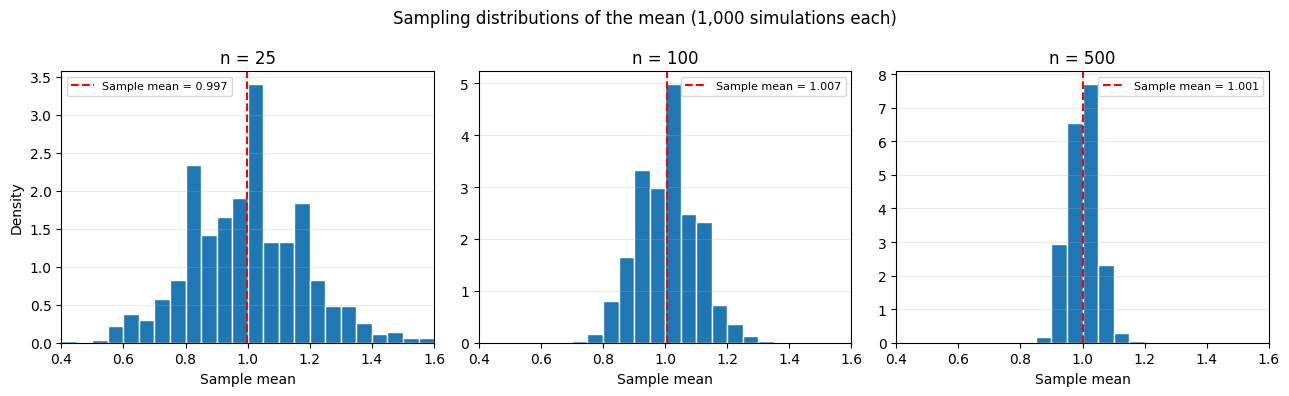

In [ ]:
# Question 2B

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(123456)
lambdas = [4, 10]
n = [25, 100, 500]
sims = 1000

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
bins = np.linspace(0.4, 1.6, 25)

for ax, n in zip(axes, n):
    observations = rng.poisson(lam=1, size=(sims, n))
    sample_means = observations.mean(axis=1)

    ax.hist(sample_means, bins=bins, density=True, edgecolor="white")
    ax.axvline(
        sample_means.mean(),
        color="red",
        linestyle="--",
        label=f"Sample mean = {sample_means.mean():.3f}",
    )
    ax.set_title(f"n = {n}")
    ax.set_xlabel("Sample mean")
    ax.set_xlim(0.4, 1.6)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Density")
fig.suptitle("Sampling distributions of the mean (1,000 simulations each)")
fig.tight_layout()
plt.show()

# We can see that the sample mean for each of distributions is centered around 1. However, as the sample size increases, the distribution is more centered and less spread out than the smaller sample sizes

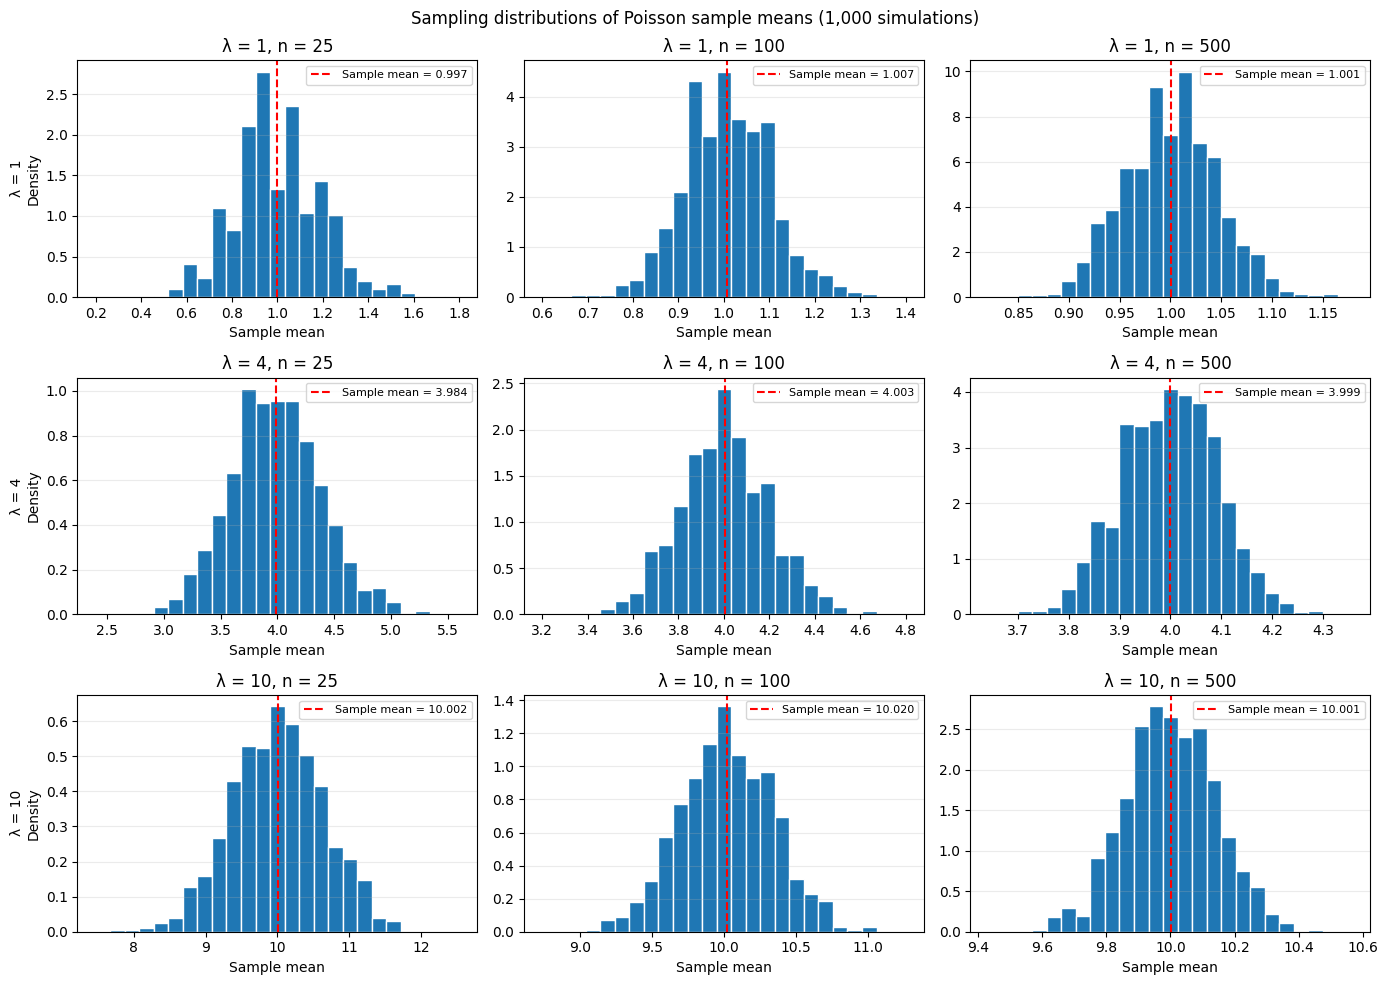

In [ ]:
# Question 2C
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(123456)
lambdas = [1, 4, 10]
n = [25, 100, 500]
sims = 1000

fig, axes = plt.subplots(3, 3, figsize=(14, 10))

for row, lam in enumerate(lambdas):
    for col, sample_size in enumerate(n):
        ax = axes[row, col]
        observations = rng.poisson(
            lam=lam, size=(sims, sample_size)
        )
        sample_means = observations.mean(axis=1)
        spread = 4 * np.sqrt(lam / sample_size)
        lower = max(0, lam - spread)
        upper = lam + spread
        bins = np.linspace(lower, upper, 26)

        ax.hist(sample_means, bins=bins, density=True, edgecolor="white")
        ax.axvline(
            sample_means.mean(),
            color="red",
            linestyle="--",
            label=f"Sample mean = {sample_means.mean():.3f}",
        )
        ax.set_title(f"λ = {lam}, n = {sample_size}")
        ax.set_xlabel("Sample mean")
        ax.grid(axis="y", alpha=0.25)
        ax.legend(fontsize=8)

    axes[row, 0].set_ylabel(f"λ = {lam}\nDensity")

fig.suptitle("Sampling distributions of Poisson sample means (1,000 simulations)")
fig.tight_layout()
plt.show()

# For each λ, as the sample size increases, the sample mean becomes less spread out and more centered around the population mean (1, 4, 10 respectively)
# If there is a larger initial skewness, it takes a larger sample size to get a more symmetric distribution of the sample mean. For example, for λ = 1, the distribution is still right-skewed at n = 25 and n = 100, but becomes more symmetric at n = 500. For λ = 4, the distribution is slightly right-skewed at n = 25, but becomes more symmetric at n = 100 and n = 500. For λ = 10, the distribution is already fairly symmetric at n = 25 and becomes even more symmetric at n = 100 and n = 500
# Although it was due to chance, in the λ = 10, n = 100 simulation, the sample mean was actually further away from the population mean than the sample mean for n = 25. Similarly, when λ = 1, n = 100, the sample mean was further away from the population mean than when n = 25. This is due to chance but I found it to be interesting that it happened

In [3]:
# Question 3A

import json
import re

import pandas as pd
import requests

PAGE_URL = "https://www.redfin.com/zipcode/60611/rentals/filter/min-beds=1,min-baths=1"
API_URL = "https://www.redfin.com/stingray/api/v1/search/rentals"

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/126.0 Safari/537.36",
    "Referer": PAGE_URL,
})

html = session.get(PAGE_URL, timeout=20).text
patterns = [r'"regionId"\s*:\s*"?(\d+)', r"region_id=(\d+)", r'\\"regionId\\":(\d+)',
            r'regionId\\?"?\s*[:=]\s*\\?"?(\d+)']
region_id = next(int(m.group(1)) for p in patterns if (m := re.search(p, html)))

params = {
    "al": 1,
    "isRentals": "true",
    "market": "chicago",
    "num_homes": 350,
    "ord": "redfin-recommended-asc",
    "page_number": 1,
    "region_id": region_id,
    "region_type": 2,
    "min_num_beds": 1,
    "min_num_baths": 1,
    "status": 9,
    "uipt": "1,2,3,4",
    "use_map_homes": "true",
    "v": 8,
}
r = session.get(API_URL, params=params, timeout=30)
homes = json.loads(r.text.removeprefix("{}&&"))["homes"]

rows = []
for h in homes:
    hd = h.get("homeData") or {}
    rx = h.get("rentalExtension") or {}
    addr = hd.get("addressInfo") or {}
    rent = rx.get("rentPriceRange") or {}
    beds = rx.get("bedRange") or {}
    baths = rx.get("bathRange") or {}
    sqft = rx.get("sqftRange") or {}
    rows.append({
        "property_name": rx.get("propertyName"),
        "address": addr.get("formattedStreetLine"),
        "zip": addr.get("zip"),
        "rent_min": rent.get("min"),
        "rent_max": rent.get("max"),
        "beds_min": beds.get("min"),
        "beds_max": beds.get("max"),
        "baths_min": baths.get("min"),
        "baths_max": baths.get("max"),
        "sqft_min": sqft.get("min"),
        "sqft_max": sqft.get("max"),
        "url": "https://www.redfin.com" + hd.get("url", ""),
    })

df = pd.DataFrame(rows)
df["rent"] = df[["rent_min", "rent_max"]].mean(axis=1)
df["is_price_range"] = df["rent_min"] != df["rent_max"]
df.to_csv("redfin_60611_rentals.csv", index=False)
print(len(df))
df.head()

231


,property_name,address,zip,rent_min,rent_max,beds_min,beds_max,baths_min,baths_max,sqft_min,sqft_max,url,rent,is_price_range
0,ReNew Waterside,420 E Ohio St,60611,2399,5339,0,3,1.0,3.0,656.0,1637.0,https://www.redfin.com/IL/Chicago/420-E-Ohio-S...,3869.0,True
1,Sienna Chicago,423 E Ohio St,60611,2725,4500,1,2,1.0,2.0,738.0,1420.0,https://www.redfin.com/IL/Chicago/423-E-Ohio-S...,3612.5,True
2,North Water Apartments,340 E North Water St,60611,2629,7809,0,3,1.0,3.0,550.0,1616.0,https://www.redfin.com/IL/Chicago/North-Water-...,5219.0,True
3,Arrive Streeterville,333 E Ontario St,60611,2059,3949,0,2,1.0,2.0,496.0,1243.0,https://www.redfin.com/IL/Chicago/333-E-Ontari...,3004.0,True
4,The Seneca Apartments,200 E Chestnut St,60611,2019,2519,0,1,1.0,1.5,265.0,775.0,https://www.redfin.com/IL/Chicago/200-E-Chestn...,2269.0,True


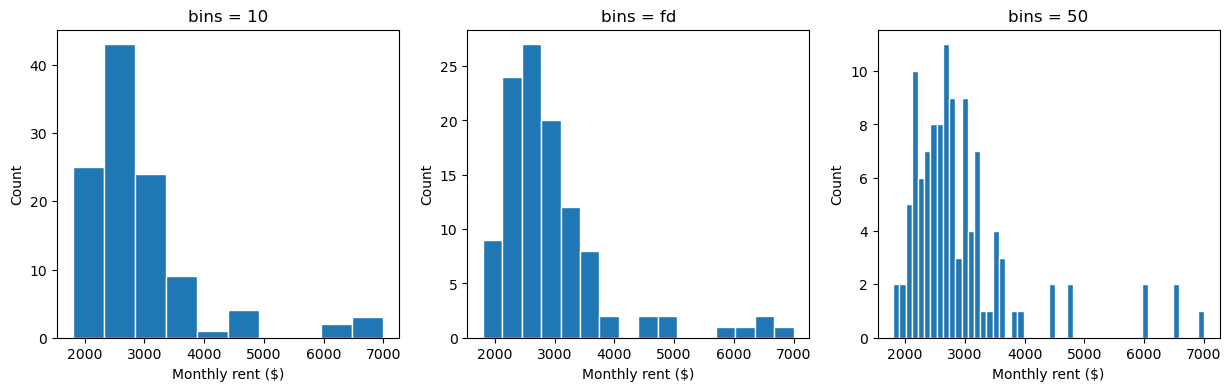

Outlier bounds: 1150 to 4350
      zip                         address  monthly_rent
47  60611       401 N Wabash Ave Unit 55G        7000.0
93  60611  460 E North Water St Unit 5104        6525.0
9   60611                  70 E Walton St        6500.0
90  60611  460 E North Water St Unit 5101        6055.0
48  60611       401 N Wabash Ave Unit 68F        6000.0
6   60611               514 N Peshtigo Ct        4750.0
31  60611                 451 E Grand Ave        4750.0
45  60611       401 N Wabash Ave Unit 41C        4500.0
69  60611             21 E Huron St #1201        4500.0


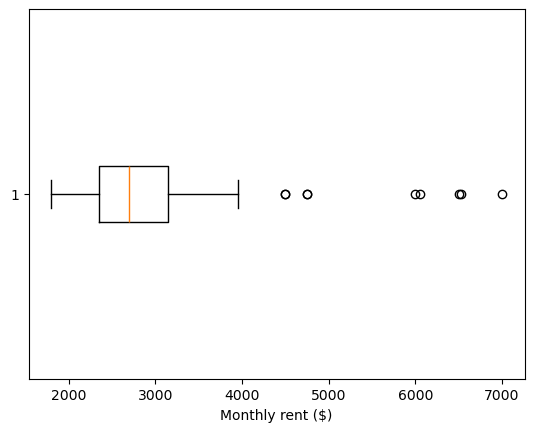

In [6]:
# Question 3B

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("redfin_60611_rentals.csv")
df = df[(df["beds_min"] == 1) & (df["zip"] == 60611)]
df["monthly_rent"] = np.where(df["is_price_range"], df["rent_min"], df["rent"])
df = df[["zip", "address", "monthly_rent"]].reset_index(drop=True)
rent = df["monthly_rent"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, bins in zip(axes, [10, "fd", 50]):
    ax.hist(rent, bins=bins, edgecolor="white")
    ax.set_title(f"bins = {bins}")
    ax.set_xlabel("Monthly rent ($)")
    ax.set_ylabel("Count")
plt.show()

q1, q3 = rent.quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr
print(f"Outlier bounds: {lower:.0f} to {upper:.0f}")

outliers = df[(rent < lower) | (rent > upper)].sort_values("monthly_rent", ascending=False)
print(outliers)

plt.boxplot(rent, vert=False)
plt.xlabel("Monthly rent ($)")
plt.show()

# Skewness: The histograms reveal that the distribution of the 60611 rental prices are right skewed. This is expected since we expect a some high end rental listings in the zip code but also a lot of lower value rentals as well.
# Outliers: As seen in the boxplot, there are a few outliers in the data, particularly on the higher end of the rent spectrum. I chose to keep the outliers since they are valid data points and represent the various rental points within the 60611 zip code.

In [5]:
# Question 3C

n = len(rent)
sample_mean = rent.mean()
sample_median = rent.median()
sample_var = rent.var(ddof=1)

print(f"n: {n}")
print(f"Sample mean: {sample_mean:.2f}")
print(f"Sample median: {sample_median:.2f}")
print(f"Sample variance: {sample_var:.2f}")

n: 111
Sample mean: 2933.41
Sample median: 2700.00
Sample variance: 912263.46


In [7]:
# Question 3D Part 1

from scipy import stats

se_clt = np.sqrt(sample_var / n)
z = stats.norm.ppf(0.975)
ci_clt = (sample_mean - z * se_clt, sample_mean + z * se_clt)

print(f"CLT standard error: {se_clt:.2f}")
print(f"95% CI: ({ci_clt[0]:.2f}, {ci_clt[1]:.2f})")

CLT standard error: 90.66
95% CI: (2755.72, 3111.09)


In [11]:
# Question 3D Part 2

rng = np.random.default_rng(123456)
B = 10000
boot_means = rng.choice(rent.to_numpy(), size=(B, n), replace=True).mean(axis=1)

se_boot = boot_means.std(ddof=1)
ci_boot_normal = (sample_mean - z * se_boot, sample_mean + z * se_boot)
ci_boot_pct = tuple(np.percentile(boot_means, [2.5, 97.5]))

print(f"Bootstrap standard error: {se_boot:.2f}")
print(f"95% CI (normal, bootstrap SE): ({ci_boot_normal[0]:.2f}, {ci_boot_normal[1]:.2f})")
print(f"95% CI (percentile): ({ci_boot_pct[0]:.2f}, {ci_boot_pct[1]:.2f})")

Bootstrap standard error: 90.76
95% CI (normal, bootstrap SE): (2755.53, 3111.29)
95% CI (percentile): (2765.80, 3120.78)


In [12]:
# Question 3D Comparison

print(pd.DataFrame({
    "SE": [se_clt, se_boot],
    "CI lower": [ci_clt[0], ci_boot_pct[0]],
    "CI upper": [ci_clt[1], ci_boot_pct[1]],
}, index=["CLT", "Bootstrap (percentile)"]).round(2))

# Looking at the results, we can see that the standard errors are similar between the two metods. The key difference between the two methods is that the CLT method assumes a normal distribution whereas Bootstrap does not. Since we know that the underlying distribution of the rental prices is right skewed, the bootstrap method is more appropriate in this case. The bootstrap method does not make any assumptions about the underlying distribution and is therefore more robust to non-normality. 
# The confience intevals are also similar between the two methods, but the bootstrap percentile method is slightly wider than the CLT method. This is expected since the bootstrap method does not assume a normal distribution and therefore has a wider confidence interval to account for the skewness in the data. 

                           SE  CI lower  CI upper
CLT                     90.66   2755.72   3111.09
Bootstrap (percentile)  90.76   2765.80   3120.78


In [ ]:
# Question 3E

rng = np.random.default_rng(123456)
B = 10000
boot_medians = np.median(rng.choice(rent.to_numpy(), size=(B, n), replace=True), axis=1)

se_median = boot_medians.std(ddof=1)
ci_median_normal = (sample_median - z * se_median, sample_median + z * se_median)
ci_median_pct = tuple(np.percentile(boot_medians, [2.5, 97.5]))

print(f"Bootstrap standard error of the median: {se_median:.2f}")
print(f"95% CI (normal approximation): ({ci_median_normal[0]:.2f}, {ci_median_normal[1]:.2f})")
print(f"95% CI (percentile): ({ci_median_pct[0]:.2f}, {ci_median_pct[1]:.2f})")

# We can see that the standard error of the median is larger than the standard error of the mean. The confidence intervals are also wider for the median than the mean. This is expected since the median is a less efficient estimator than the mean, especially for right skewed distributions. 

Bootstrap standard error of the median: 61.73
95% CI (normal approximation): (2579.01, 2820.99)
95% CI (percentile): (2599.00, 2800.00)


In [ ]:
# Question 3F

summary = pd.DataFrame({
    "Estimate": [sample_mean, sample_mean, sample_mean, sample_median, sample_median],
    "SE": [se_clt, se_boot, se_boot, se_median, se_median],
    "CI lower": [ci_clt[0], ci_boot_normal[0], ci_boot_pct[0], ci_median_normal[0], ci_median_pct[0]],
    "CI upper": [ci_clt[1], ci_boot_normal[1], ci_boot_pct[1], ci_median_normal[1], ci_median_pct[1]],
}, index=["Mean, CLT", "Mean, bootstrap normal", "Mean, bootstrap percentile",
          "Median, bootstrap normal", "Median, bootstrap percentile"])
summary["CI width"] = summary["CI upper"] - summary["CI lower"]
print(summary.round(2))

# Recommendation: I would recommend the median using bootstrap percentile method. This is because that method describes the typical renter's experience better in comparison to that of the mean. The mean is more inflated and less resistant to outliers (which we have in our dataset). Also assuming a normal distribution with the bootstrap method simply makes the intervals wider. We know that the underlying data is right skewed so the normal approach fails to capture the true nature of the data. All these reasons make the median with bootstrap percentile method the best approach to pitch to buyers. 

                              Estimate     SE  CI lower  CI upper  CI width
Mean, CLT                      2933.41  90.66   2755.72   3111.09    355.37
Mean, bootstrap normal         2933.41  90.76   2755.53   3111.29    355.76
Mean, bootstrap percentile     2933.41  90.76   2765.80   3120.78    354.99
Median, bootstrap normal       2700.00  61.73   2579.01   2820.99    241.98
Median, bootstrap percentile   2700.00  61.73   2599.00   2800.00    201.00


**Generative AI Use:**  

I used Claude and Copilot to primarily help me with syntax, especially with the web scraping on Redfin. I was struggling with getting the scraper to work initially by using BeautifulSoup and was getting blocked by Redfin's servers from scraping properly. GenAI helped me identify that the issue was actually in the kernel I was using (I initially was using a Google Colab kernel and that was restricted by Redfin's robots.txt) so I was able to switch to a personal kernel and finish Problem 3 as expected.